In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())

In [3]:
np.random.seed(42)
normal = np.vstack([np.random.normal([0,0],0.8,(150,2)), np.random.normal([5,5],0.8,(150,2))])
anom = np.random.uniform(-6,11,(15,2))
X = np.vstack([normal,anom]); true = np.array([0]*300+[1]*15)       # 1 = real anomaly
df = pd.DataFrame(X,columns=["f1","f2"]); print(df.describe())

               f1          f2
count  315.000000  315.000000
mean     2.472129    2.598874
std      2.744158    2.702296
min     -5.692127   -3.406836
25%     -0.003354    0.130037
50%      2.600108    3.556094
75%      5.061269    4.890991
max      9.846011   10.103817


In [4]:
z = np.abs((df-df.mean())/df.std())
pred = {"Z-score": (z>2.5).any(axis=1).astype(int).values,
        "Isolation Forest": (IsolationForest(contamination=0.05,random_state=42).fit_predict(X)==-1).astype(int),
        "LOF": (LocalOutlierFactor(n_neighbors=20,contamination=0.05).fit_predict(X)==-1).astype(int)}

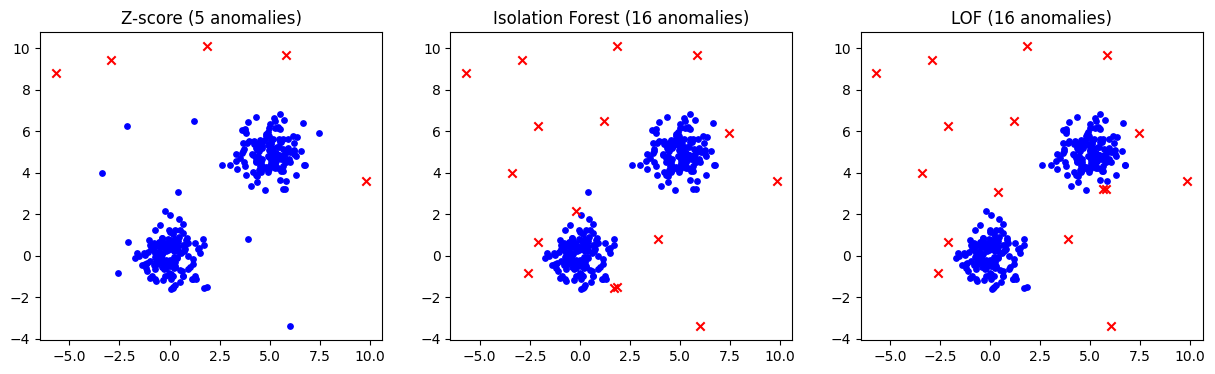

Z-score            Precision=1.00 Recall=0.33 F1=0.50
Isolation Forest   Precision=0.62 Recall=0.67 F1=0.65
LOF                Precision=0.69 Recall=0.73 F1=0.71


In [5]:
fig,ax = plt.subplots(1,3,figsize=(15,4))
for a,(name,p) in zip(ax,pred.items()):
    a.scatter(X[p==0,0],X[p==0,1],c="blue",s=15); a.scatter(X[p==1,0],X[p==1,1],c="red",marker="x")
    a.set_title(f"{name} ({p.sum()} anomalies)")
plt.show()
for name,p in pred.items():
    print(f"{name:<18} Precision={precision_score(true,p):.2f} Recall={recall_score(true,p):.2f} F1={f1_score(true,p):.2f}")